<center><h1>Peng_Yu-Hsuan_HW4</h1></center>
<br>
<br>

Name: Yu-Hsuan Peng
<br>
Github Username: Vincent2k0624
<br>
USC ID: 1889-9849-82

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.feature_selection import RFECV

from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, auc
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [2]:
all_files = sorted(glob.glob('AReM/*/dataset*.csv'))
all_valid = True

for file in all_files:
    data = pd.read_csv(file, skiprows = 4, usecols = range(1, 7))
    if data.shape != (480, 6) or data.isna().any().any():
        all_valid = False
        print('Invalid file:', file, data.shape)

print('Number of files:', len(all_files))
print('All files have shape (480, 6) and no missing values:', all_valid)

Number of files: 88
All files have shape (480, 6) and no missing values: True


### (b) Splitting Data

In [3]:
train_files = []
test_files = []

for file in all_files:
    file_path = Path(file)

    activity = file_path.parent.name
    dataset_number = int(file_path.stem.replace('dataset', ''))

    is_test = (activity.startswith('bending') and dataset_number <= 2) or (not activity.startswith('bending') and dataset_number <= 3)

    if is_test:
        test_files.append(file)
    else:
        train_files.append(file)

print('Number of training:', len(train_files))
print('Number of testing:', len(test_files))

Number of training: 69
Number of testing: 19


### (c) Feature Extraction

In [4]:
all_features = []
for file in all_files:
    data = pd.read_csv(file, skiprows = 4, usecols = range(1, 7))

    features = {}

    for i, column in enumerate(data.columns, start = 1):
        series = data[column]

        features[f'min{i}'] = series.min()
        features[f'max{i}'] = series.max()
        features[f'mean{i}'] = series.mean()
        features[f'median{i}'] = series.median()
        features[f'std{i}'] = series.std()
        features[f'1st_quart{i}'] = series.quantile(0.25)
        features[f'3rd_quart{i}'] = series.quantile(0.75)

    all_features.append(features)

time_domain_features = pd.DataFrame(all_features)
time_domain_features.insert(0, 'Instance', range(1, len(time_domain_features) + 1))

print(time_domain_features.shape)
display(time_domain_features.head())

(88, 43)


,Instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

Activity
other      60
bending     9
Name: count, dtype: int64


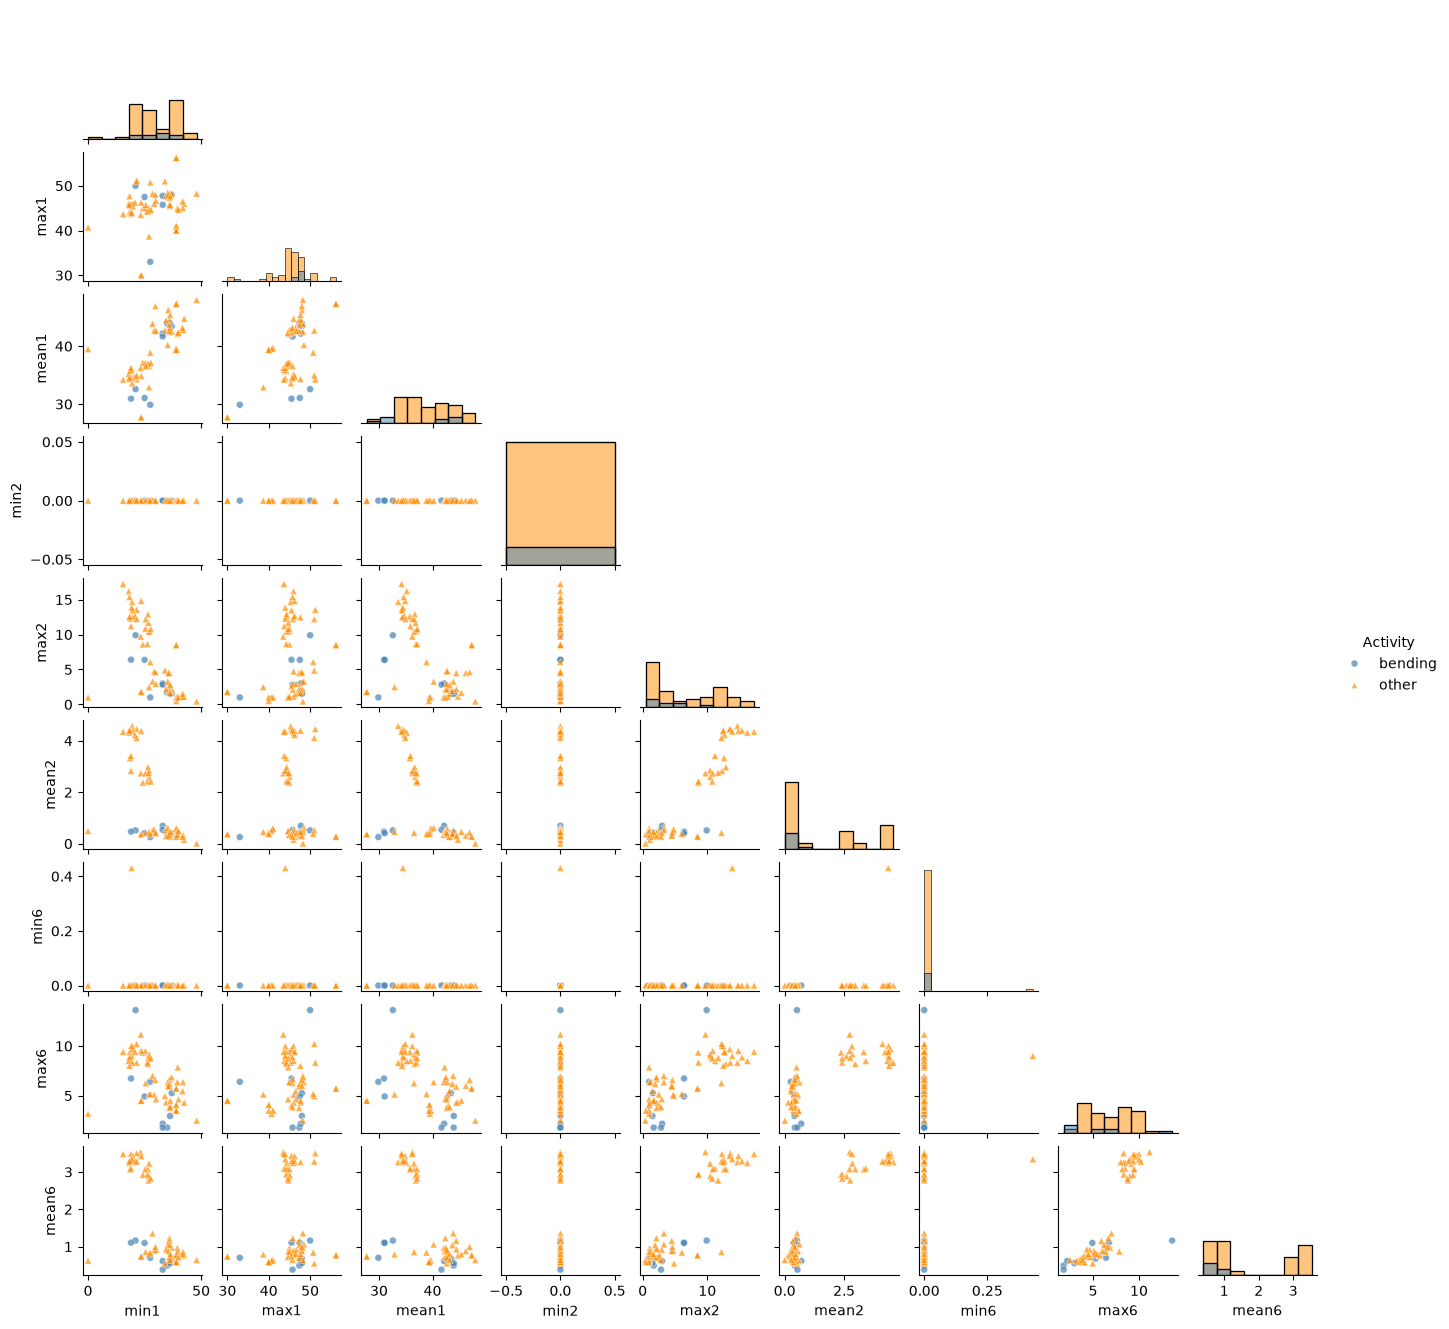

In [5]:
plot_rows = []

for file in train_files:
    data = pd.read_csv(file, skiprows = 4, usecols = range(1, 7))

    features = {}

    for i in [1, 2, 6]:
        series = data.iloc[:, i - 1]

        features[f'min{i}'] = series.min()
        features[f'max{i}'] = series.max()
        features[f'mean{i}'] = series.mean()

    activity = Path(file).parent.name

    if activity.startswith('bending'):
        features['Activity'] = 'bending'
    else:
        features['Activity'] = 'other'

    plot_rows.append(features)

plot_data = pd.DataFrame(plot_rows)

print(plot_data['Activity'].value_counts())

sns.pairplot(plot_data, hue = 'Activity', hue_order = ['bending', 'other'],
              markers = ['o', '^'],  palette = {'bending' : 'steelblue', 'other' : 'darkorange'},
            diag_kind = 'hist', corner = True, height = 1.5, plot_kws = {'alpha' : 0.7, 's' : 25})

plt.show()

#### ii. Splitted Plots

(69, 19)
Activity
other      60
bending     9
Name: count, dtype: int64


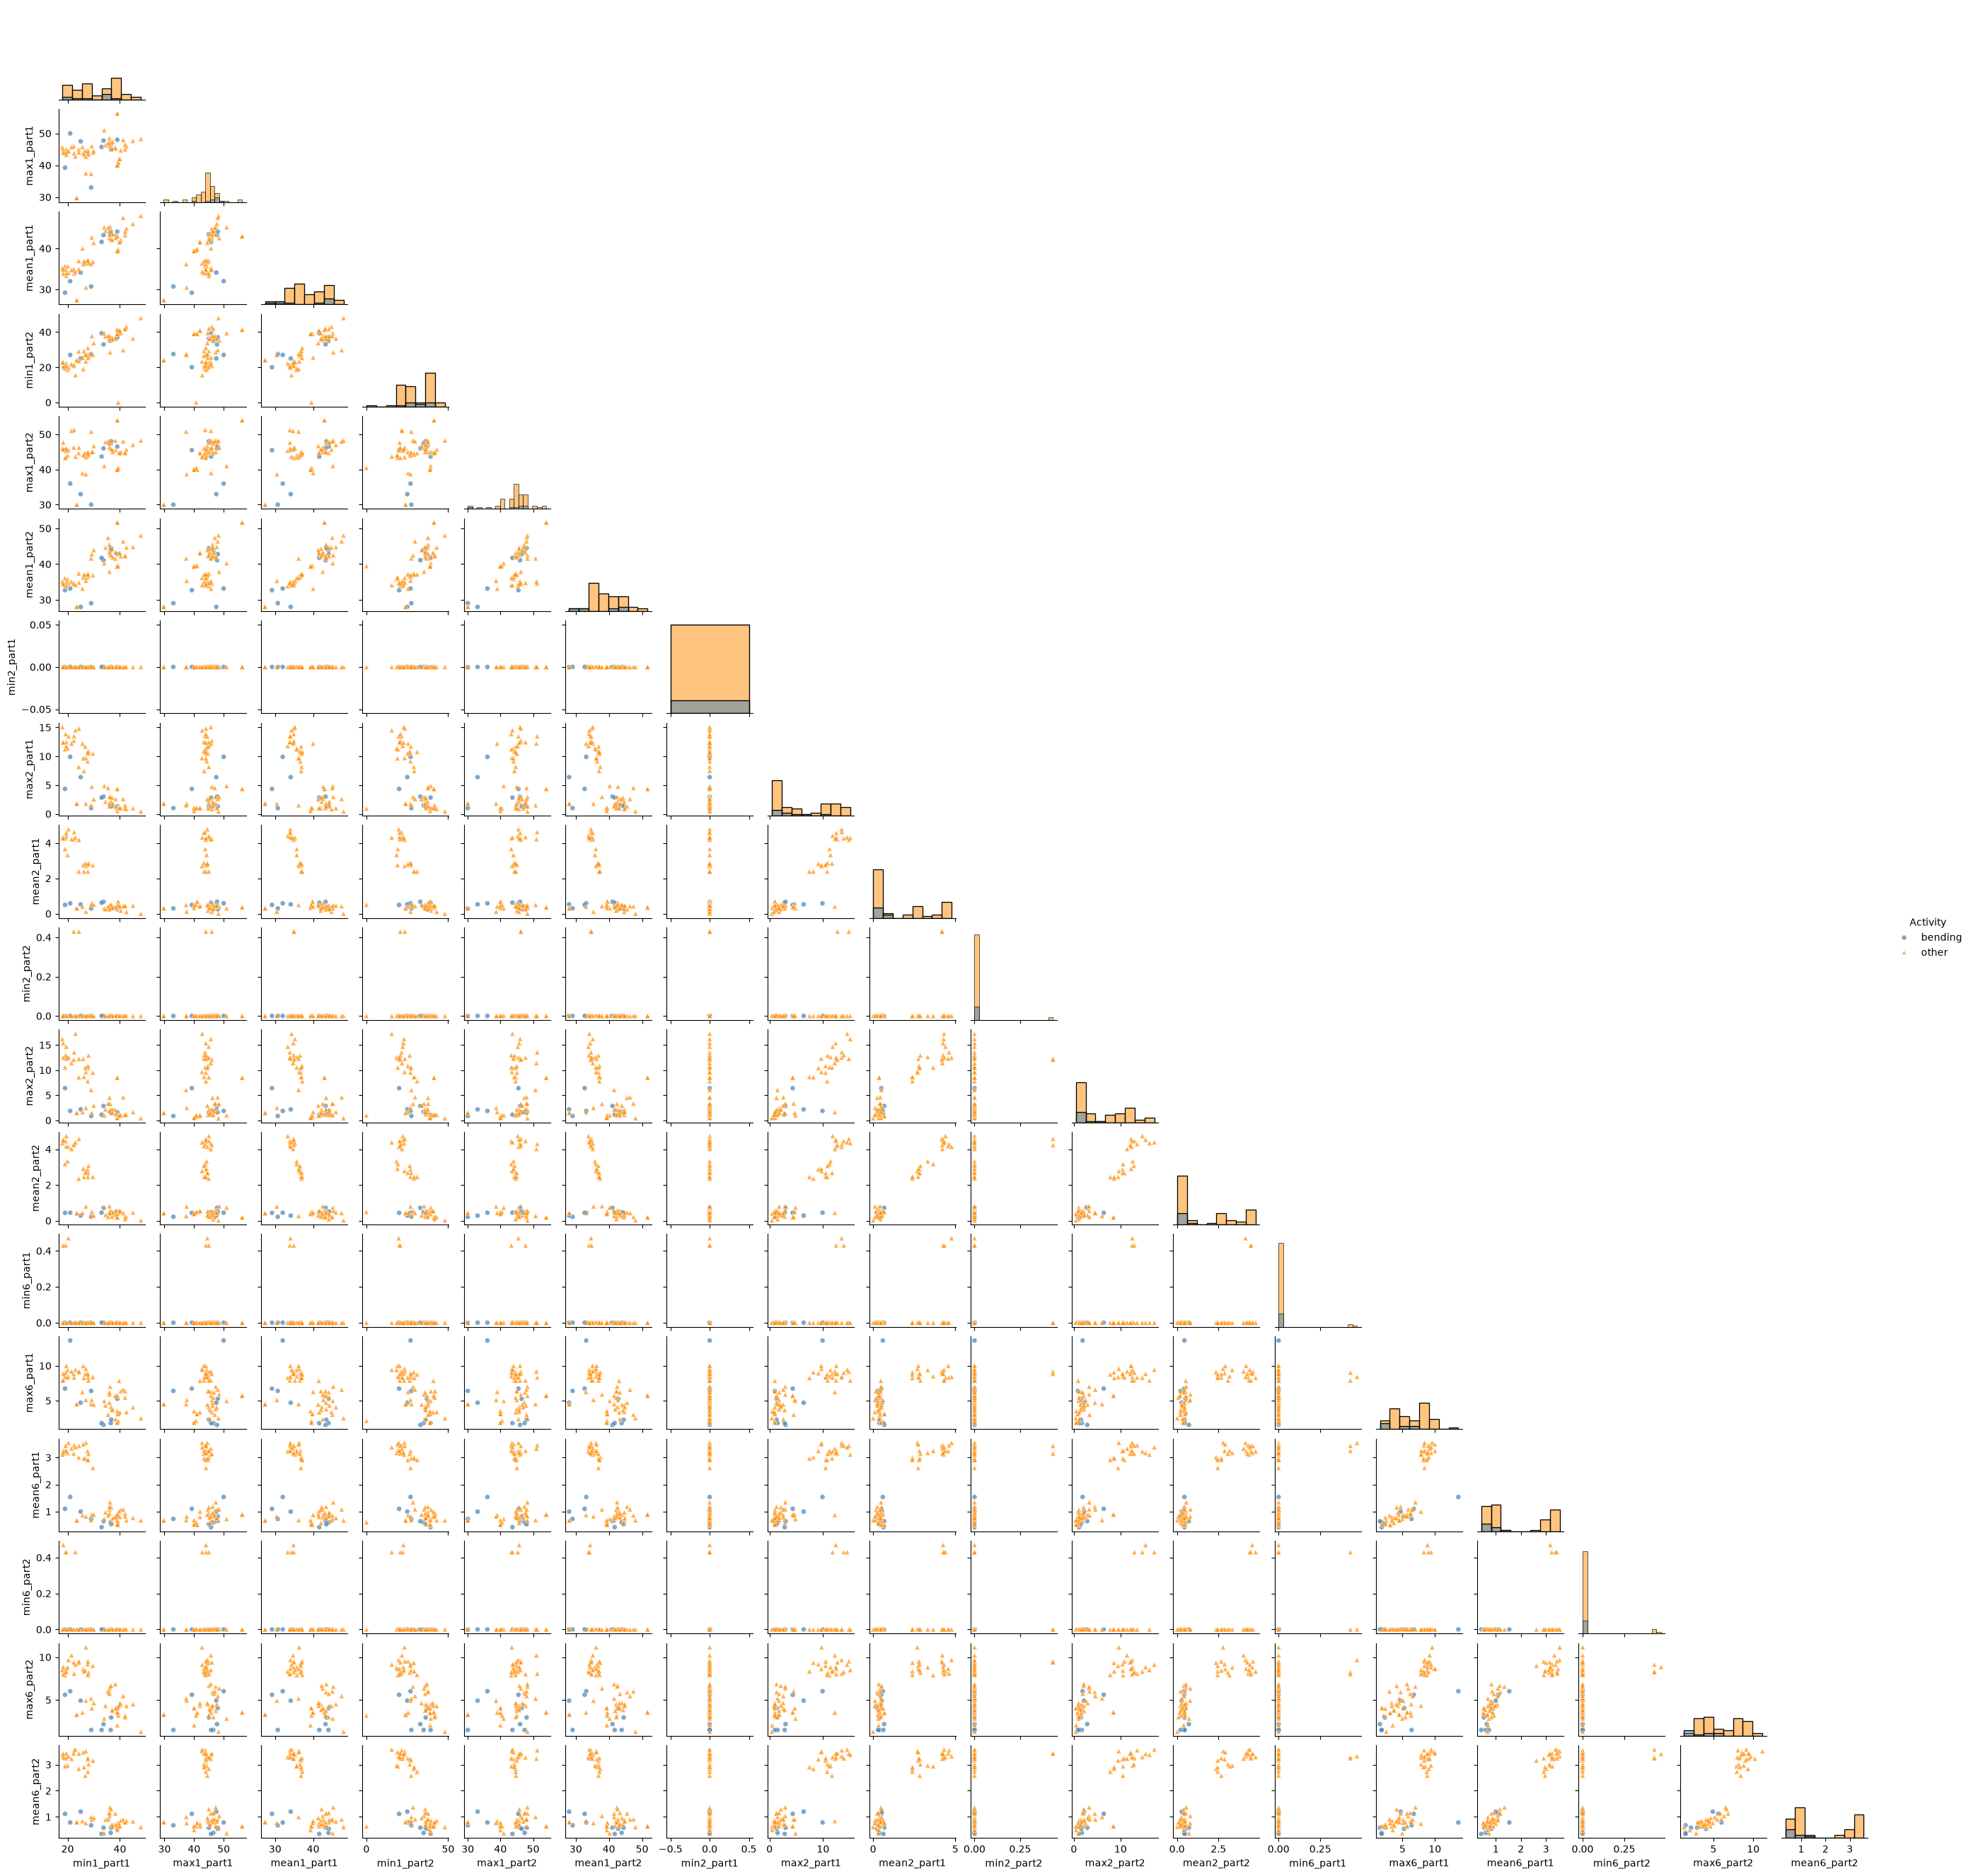

In [6]:
split_rows = []

for file in train_files:
    data = pd.read_csv(file, skiprows = 4, usecols = range(1, 7))

    features = {}

    for i in [1, 2, 6]:
        series = data.iloc[:, i - 1]

        midpoint = len(series) // 2
        parts = [series.iloc[: midpoint], series.iloc[midpoint :]]

        for part_number, part in enumerate(parts, start = 1):
            features[f'min{i}_part{part_number}'] = part.min()
            features[f'max{i}_part{part_number}'] = part.max()
            features[f'mean{i}_part{part_number}'] = part.mean()

    activity = Path(file).parent.name

    if activity.startswith('bending'):
        features['Activity'] = 'bending'
    else:
        features['Activity'] = 'other'

    split_rows.append(features)

split_plot_data = pd.DataFrame(split_rows)

print(split_plot_data.shape)
print(split_plot_data['Activity'].value_counts())

sns.pairplot(split_plot_data, hue = 'Activity', hue_order = ['bending', 'other'],
              markers = ['o', '^'],  palette = {'bending' : 'steelblue', 'other' : 'darkorange'},
            diag_kind = 'hist', corner = True, height = 1.5, plot_kws = {'alpha' : 0.7, 's' : 25})

plt.show()

After splitting the time series into two halves, there is no noticeable improvement in class separation. Bending and other activities still overlap.

#### iii. Time Series Segments

In [7]:
def extract_features(files, l):
    all_features = []
    labels = []
    
    for file in files:
        data = pd.read_csv(file, skiprows = 4, usecols = range(1, 7))
        parts = np.array_split(data.to_numpy(), l)
        features = {}

        for part_number, part in enumerate(parts, start = 1):
            part = pd.DataFrame(part)

            for i in range(1, 7):
                series = part.iloc[:, i - 1]

                features[f'min{i}_part{part_number}'] = series.min()
                features[f'max{i}_part{part_number}'] = series.max()
                features[f'mean{i}_part{part_number}'] = series.mean()
                features[f'median{i}_part{part_number}'] = series.median()
                features[f'std{i}_part{part_number}'] = series.std()
                features[f'1st_quart{i}_part{part_number}'] = series.quantile(0.25)
                features[f'3rd_quart{i}_part{part_number}'] = series.quantile(0.75)

        all_features.append(features)

        activity = Path(file).parent.name

        if activity.startswith('bending'):
            labels.append(1)
        else:
            labels.append(0)

    X = pd.DataFrame(all_features)
    y = np.array(labels)

    return X, y

In [8]:
X_train, y_train = extract_features(train_files, l = 2)

print('Feature shape:', X_train.shape)
print('Bending:', np.sum(y_train == 1))
print('other:', np.sum(y_train == 0))

Feature shape: (69, 84)
Bending: 9
other: 60


In [9]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
logistic = LogisticRegression(C = 1e6, max_iter = 2000)

model = Pipeline([('scaler', StandardScaler()), ('rfe', RFE(estimator = logistic, n_features_to_select = 5))])
scores = cross_val_score(model, X_train, y_train, cv = cv, scoring = 'accuracy')

print('Accuracy of each fold:', scores)
print('Mean CV accuracy:', scores.mean())

Accuracy of each fold: [1.         1.         0.92857143 0.85714286 1.        ]
Mean CV accuracy: 0.9571428571428573


In [10]:
results = []
best_score = -1

for l in range(1, 21):
    print(f'Trying l = {l}...', flush = True)

    X, y = extract_features(train_files, l)

    estimator = Pipeline([('scaler', StandardScaler()), ('logistic', LogisticRegression(C = 1e6, max_iter = 2000))])

    selector = RFECV(estimator = estimator, step = 1, min_features_to_select = 1, cv = cv, scoring = 'accuracy', importance_getter = 'named_steps.logistic.coef_', n_jobs = -1)

    selector.fit(X, y)

    p = selector.n_features_
    score = selector.cv_results_['mean_test_score'].max()

    results.append({'l' : l, 'p' : p, 'CV Accuracy' : score})

    if score > best_score:
        best_score = score
        best_l = l
        best_p = p
        best_selector = selector

    print(f'l = {l}, p = {p}, CV accuracy = {score : .4f}')

results_df = pd.DataFrame(results)
display(results_df)

print('Best l:', best_l)
print('Best p:', best_p)
print('Best CV accuracy:', best_score)

Trying l = 1...
l = 1, p = 16, CV accuracy =  0.9857
Trying l = 2...
l = 2, p = 6, CV accuracy =  0.9714
Trying l = 3...
l = 3, p = 6, CV accuracy =  0.9429
Trying l = 4...
l = 4, p = 9, CV accuracy =  0.9571
Trying l = 5...
l = 5, p = 1, CV accuracy =  0.9571
Trying l = 6...
l = 6, p = 5, CV accuracy =  0.9571
Trying l = 7...
l = 7, p = 8, CV accuracy =  0.9571
Trying l = 8...
l = 8, p = 2, CV accuracy =  0.9714
Trying l = 9...
l = 9, p = 10, CV accuracy =  0.9429
Trying l = 10...
l = 10, p = 8, CV accuracy =  0.9714
Trying l = 11...
l = 11, p = 5, CV accuracy =  0.9571
Trying l = 12...
l = 12, p = 1, CV accuracy =  0.9571
Trying l = 13...
l = 13, p = 11, CV accuracy =  0.9429
Trying l = 14...
l = 14, p = 3, CV accuracy =  0.9571
Trying l = 15...
l = 15, p = 2, CV accuracy =  0.9571
Trying l = 16...
l = 16, p = 8, CV accuracy =  0.9429
Trying l = 17...
l = 17, p = 5, CV accuracy =  0.9714
Trying l = 18...
l = 18, p = 3, CV accuracy =  0.9571
Trying l = 19...
l = 19, p = 2, CV accuracy

,l,p,CV Accuracy
0,1,16,0.985714
1,2,6,0.971429
2,3,6,0.942857
3,4,9,0.957143
4,5,1,0.957143
5,6,5,0.957143
6,7,8,0.957143
7,8,2,0.971429
8,9,10,0.942857
9,10,8,0.971429


Best l: 1
Best p: 16
Best CV accuracy: 0.9857142857142858


The best combination is $l=1$ and $p=16$, with a mean CV accuracy of 98.57%. Standardization and feature selection are fitted within each training fold. Applying them to the entire training set before cross-validation would leak validation information. Stratified CV approximately preserves class proportions across folds.

#### iv. Confusion Matrix

Training accuracy: 1.0
Training AUC: 1.0


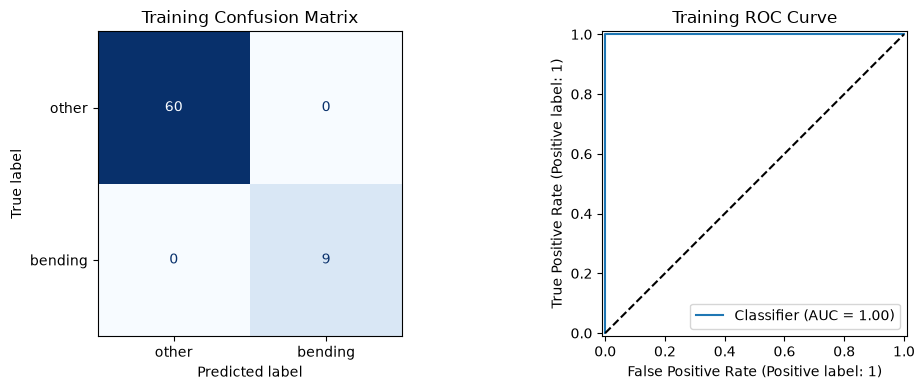

In [11]:
X_train, y_train = extract_features(train_files, best_l)

train_predictions = best_selector.predict(X_train)
train_probabilities = best_selector.predict_proba(X_train)[:, 1]

print('Training accuracy:', accuracy_score(y_train, train_predictions))
print('Training AUC:', roc_auc_score(y_train, train_probabilities))

fig, axes = plt.subplots(1, 2, figsize = (11, 4))

ConfusionMatrixDisplay.from_predictions(y_train, train_predictions, labels = [0, 1], display_labels = ['other', 'bending'], cmap = 'Blues', colorbar = False, ax = axes[0])

axes[0].set_title('Training Confusion Matrix')

RocCurveDisplay.from_predictions(y_train, train_probabilities, ax = axes[1])

axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Training ROC Curve')

plt.tight_layout()
plt.show()

In [12]:
selected_features = X_train.columns[best_selector.support_]

final_logistic = best_selector.estimator_.named_steps['logistic']

coefficient_table = pd.DataFrame({'Feature' : ['Intercept'] + selected_features.tolist(), 'Coefficient' : np.concatenate([final_logistic.intercept_, final_logistic.coef_[0]])})

coefficient_table['p-value'] = 'N/A (complete separation)'
display(coefficient_table)

,Feature,Coefficient,p-value
0,Intercept,-10.972780,N/A (complete separation)
1,min1_part1,-1.937793,N/A (complete separation)
2,max1_part1,1.709278,N/A (complete separation)
3,mean1_part1,-1.239359,N/A (complete separation)
4,3rd_quart1_part1,-2.925989,N/A (complete separation)
5,max2_part1,-2.048019,N/A (complete separation)
6,max3_part1,0.751190,N/A (complete separation)
7,3rd_quart3_part1,-2.292143,N/A (complete separation)
8,max4_part1,2.173464,N/A (complete separation)
9,median4_part1,-1.155283,N/A (complete separation)


In [13]:
decision_scores = best_selector.decision_function(X_train)

signed_margins = (2 * y_train - 1) * decision_scores

print('Minimum signed margin:', signed_margins.min())
print('Complete separation:', np.all(signed_margins > 0))

Minimum signed margin: 5.676882569734346
Complete separation: True


Complete separation prevents reliable conventional p-values. The reported coefficients use weak L2 regularization ($C=10^6$) and correspond to standardized features.

#### v. Test Classifier

Test feature shape: (19, 42)
Test accuracy: 1.0
CV accuracy: 0.9857142857142858


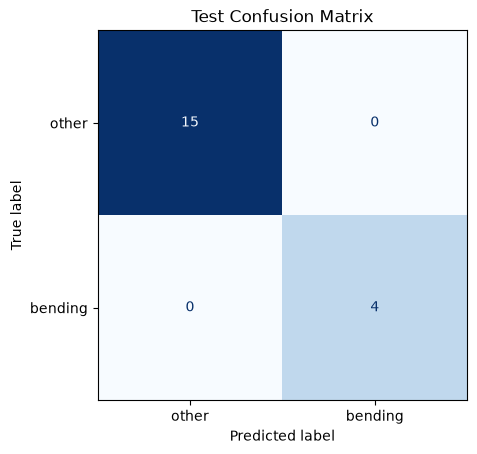

In [14]:
X_test, y_test = extract_features(test_files, best_l)

test_predictions = best_selector.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

print('Test feature shape:', X_test.shape)
print('Test accuracy:', test_accuracy)
print('CV accuracy:', best_score)

ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, 
                                        labels = [0, 1], 
                                        display_labels = ['other', 'bending'], 
                                        cmap = 'Blues', colorbar = False)

plt.title('Test Confusion Matrix')
plt.show()

The test accuracy is 100%, slightly higher than the cross-validation accuracy of 98.57%. All 19 test instances are correctly classified.

#### vi. Separation

Yes. The selected features completely separate the training classes, causing instability in unregularized logistic regression estimates.

#### vii. Imbalance

In [15]:
X_selected = X_train[selected_features]

bending_indices = np.where(y_train == 1)[0]
other_indices = np.where(y_train == 0)[0]

rng = np.random.default_rng(42)

sampled_other = rng.choice(other_indices, size = len(bending_indices), replace = False)

sample_indices = np.concatenate([bending_indices, sampled_other])

X_sample = X_selected.iloc[sample_indices]
y_sample = y_train[sample_indices]

case_control_model = Pipeline([('scaler', StandardScaler()), ('logistic', LogisticRegression(C = 1e6, max_iter = 2000))])

case_control_model.fit(X_sample, y_sample)

original_proportion = y_train.mean()
sample_proportion = y_sample.mean()

adjustment = (np.log(original_proportion / (1 - original_proportion)) - np.log(sample_proportion / (1 - sample_proportion)))

case_control_model.named_steps['logistic'].intercept_ += adjustment

print('Sample bending:', np.sum(y_sample == 1))
print('Sample other:', np.sum(y_sample == 0))
print('Intercept adjustment:', adjustment)

Sample bending: 9
Sample other: 9
Intercept adjustment: -1.8971199848858813


Training accuracy: 1.0
Training AUC: 1.0
Test accuracy: 1.0
Test AUC: 1.0


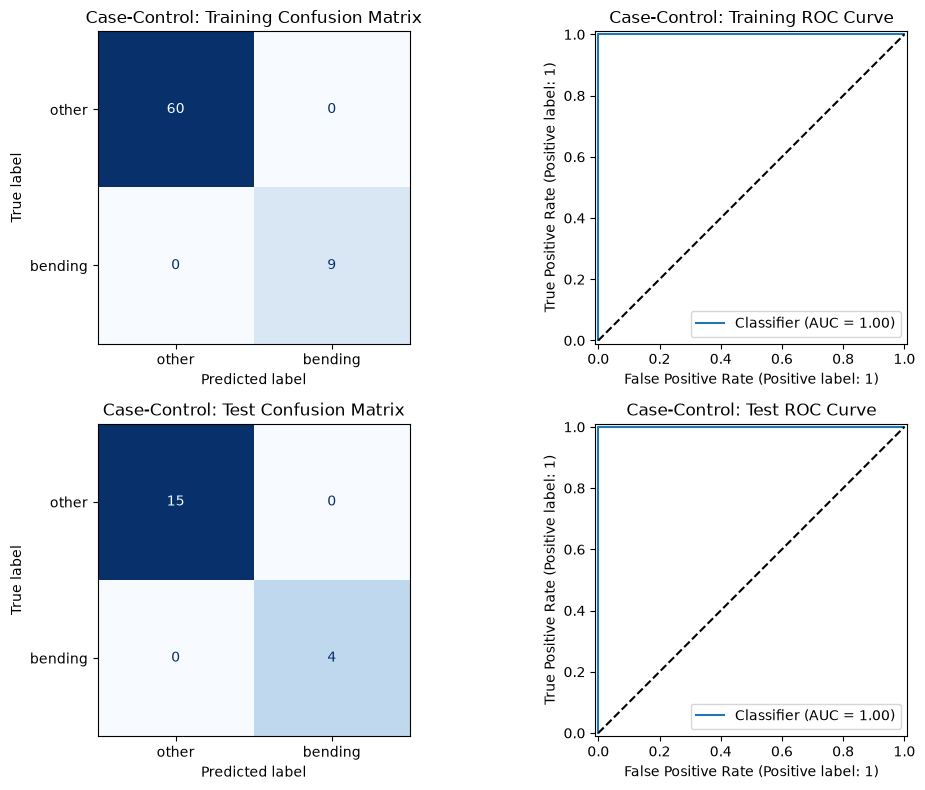

In [16]:
fig, axes = plt.subplots(2, 2, figsize = (11, 8))

datasets = [('Training', X_train, y_train), ('Test', X_test, y_test)]

for row, (name, X, y) in enumerate(datasets):
    X_selected_data = X[selected_features]

    predictions = case_control_model.predict(X_selected_data)
    probabilities = case_control_model.predict_proba(X_selected_data)[:, 1]

    print(f'{name} accuracy:', accuracy_score(y, predictions))
    print(f'{name} AUC:', roc_auc_score(y, probabilities))

    ConfusionMatrixDisplay.from_predictions(y, predictions, labels = [0, 1], display_labels = ['other', 'bending'], cmap = 'Blues', colorbar = False, ax = axes[row, 0])
    axes[row, 0].set_title(f'Case-Control: {name} Confusion Matrix')

    RocCurveDisplay.from_predictions(y, probabilities, ax = axes[row, 1])

    axes[row, 1].plot([0, 1], [0, 1], 'k--')
    axes[row, 1].set_title(f'Case-Control: {name} ROC Curve')

plt.tight_layout()
plt.show()

The training classes are imbalanced, with 60 other instances and 9 bending instances. I sampled 9 instances from each class and adjusted the intercept. The model achieved 100% accuracy and an AUC of 1.00 on both training and test sets.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [17]:
l1_results = []
best_l1_score = -1

for l in range(1, 21):
    X, y = extract_features(train_files, l)

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logistic', LogisticRegression(
            l1_ratio = 1,
            solver = 'liblinear',
            max_iter = 5000,
            random_state = 42
        ))
    ])

    search = GridSearchCV(
        estimator = model,
        param_grid = {
            'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
        },
        cv = cv,
        scoring = 'accuracy',
        n_jobs = -1
    )

    search.fit(X, y)

    C = search.best_params_['logistic__C']
    score = search.best_score_

    l1_results.append({
        'l': l,
        'C': C,
        'CV Accuracy': score
    })

    if score > best_l1_score:
        best_l1_score = score
        best_l1_l = l
        best_l1_C = C
        best_l1_model = search.best_estimator_

    print(f'l = {l}, C = {C}, CV accuracy = {score:.4f}')

l1_results_df = pd.DataFrame(l1_results)
display(l1_results_df)

print('Best l:', best_l1_l)
print('Best C:', best_l1_C)
print('Best CV accuracy:', best_l1_score)

l = 1, C = 1000, CV accuracy = 0.9714
l = 2, C = 10, CV accuracy = 0.9714
l = 3, C = 1, CV accuracy = 0.9571
l = 4, C = 1000, CV accuracy = 0.9571
l = 5, C = 100, CV accuracy = 0.9418
l = 6, C = 10, CV accuracy = 0.9571
l = 7, C = 100, CV accuracy = 0.9560
l = 8, C = 100, CV accuracy = 0.9429
l = 9, C = 10, CV accuracy = 0.9418
l = 10, C = 100, CV accuracy = 0.9714
l = 11, C = 1, CV accuracy = 0.9571
l = 12, C = 1, CV accuracy = 0.9714
l = 13, C = 1, CV accuracy = 0.9571
l = 14, C = 1, CV accuracy = 0.9571
l = 15, C = 1000, CV accuracy = 0.9429
l = 16, C = 100, CV accuracy = 0.9429
l = 17, C = 100, CV accuracy = 0.9429
l = 18, C = 1, CV accuracy = 0.9571
l = 19, C = 100, CV accuracy = 0.9714
l = 20, C = 1, CV accuracy = 0.9571


,l,C,CV Accuracy
0,1,1000,0.971429
1,2,10,0.971429
2,3,1,0.957143
3,4,1000,0.957143
4,5,100,0.941758
5,6,10,0.957143
6,7,100,0.956044
7,8,100,0.942857
8,9,10,0.941758
9,10,100,0.971429


Best l: 1
Best C: 1000
Best CV accuracy: 0.9714285714285715


In [18]:
X_test_l1, y_test_l1 = extract_features(test_files, best_l1_l)

l1_test_predictions = best_l1_model.predict(X_test_l1)
l1_test_accuracy = accuracy_score(y_test_l1, l1_test_predictions)

l1_coefficients = best_l1_model.named_steps['logistic'].coef_[0]

print('L1 test accuracy:', l1_test_accuracy)
print('Number of nonzero coefficients:', np.count_nonzero(l1_coefficients))

L1 test accuracy: 1.0
Number of nonzero coefficients: 17


#### ii. Comparison

RFE achieved slightly higher cross-validation accuracy than L1 (98.57% vs. 97.14%), while both achieved 100% test accuracy. L1 is easier to implement because it performs feature selection automatically during model fitting.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [19]:
def extract_multiclass_feature(files, l):
    X, _ = extract_features(files, l)

    labels = []

    for file in files:
        activity = Path(file).parent.name
        labels.append(activity)

    y = np.array(labels)

    return X, y

In [20]:
X_train_multi, y_train_multi = extract_multiclass_feature(train_files, l = 1)

print('Feature shape:', X_train_multi.shape)
print(pd.Series(y_train_multi).value_counts())

Feature shape: (69, 42)
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


In [21]:
cv_multi = StratifiedKFold(n_splits = 4, shuffle = True, random_state = 42)

multi_results = []
best_multi_score = -1

for l in range(1, 21):
    X, y = extract_multiclass_feature(train_files, l)

    model = Pipeline([('scaler', StandardScaler()), ('logistic', LogisticRegression(l1_ratio = 1, solver = 'saga', max_iter = 20000, tol = 0.001, random_state = 42))])

    search = GridSearchCV(estimator = model, param_grid = {'logistic__C' : [0.001, 0.01, 0.1, 1, 10, 100, 1000]}, cv = cv_multi, scoring = 'accuracy', n_jobs = -1)

    search.fit(X, y)

    C = search.best_params_['logistic__C']
    score = search.best_score_

    multi_results.append({'l' : l, 'C' : C, 'CV Accuracy' : score})

    if score > best_multi_score:
        best_multi_score = score
        best_multi_l = l
        best_multi_C = C
        best_multi_model = search.best_estimator_

    print(f'l = {l}, C = {C}, CV accuracy = {score : .4f}')

multi_results_df = pd.DataFrame(multi_results)
display(multi_results_df)

print('Best l:', best_multi_l)
print('Best C:', best_multi_C)
print('Best CV accuracy:', best_multi_score)

l = 1, C = 100, CV accuracy =  0.8987
l = 2, C = 100, CV accuracy =  0.9142
l = 3, C = 10, CV accuracy =  0.8415
l = 4, C = 100, CV accuracy =  0.8554
l = 5, C = 100, CV accuracy =  0.8832
l = 6, C = 100, CV accuracy =  0.8979
l = 7, C = 10, CV accuracy =  0.8399
l = 8, C = 100, CV accuracy =  0.8685
l = 9, C = 10, CV accuracy =  0.8554
l = 10, C = 10, CV accuracy =  0.8538
l = 11, C = 10, CV accuracy =  0.7672
l = 12, C = 100, CV accuracy =  0.8260
l = 13, C = 100, CV accuracy =  0.8260
l = 14, C = 1, CV accuracy =  0.8113
l = 15, C = 100, CV accuracy =  0.8685
l = 16, C = 1, CV accuracy =  0.8096
l = 17, C = 100, CV accuracy =  0.8113
l = 18, C = 10, CV accuracy =  0.8832
l = 19, C = 1000, CV accuracy =  0.8113
l = 20, C = 1, CV accuracy =  0.8391


,l,C,CV Accuracy
0,1,100,0.898693
1,2,100,0.914216
2,3,10,0.841503
3,4,100,0.855392
4,5,100,0.883170
5,6,100,0.897876
6,7,10,0.839869
7,8,100,0.868464
8,9,10,0.855392
9,10,10,0.853758


Best l: 2
Best C: 100
Best CV accuracy: 0.9142156862745099


Test accuracy: 0.8421052631578947
Test error: 0.1578947368421053


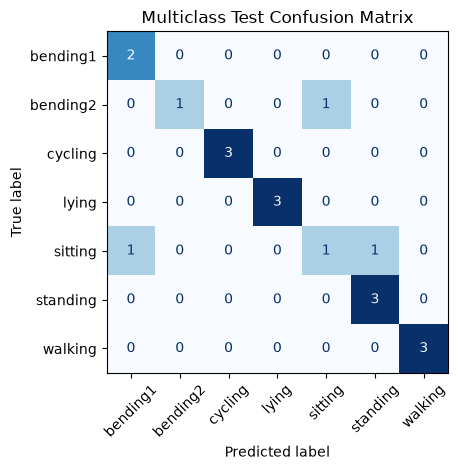

In [22]:
X_test_multi, y_test_multi = extract_multiclass_feature(test_files, best_multi_l)

multi_predictions = best_multi_model.predict(X_test_multi)

multi_test_accuracy = accuracy_score(y_test_multi, multi_predictions)
multi_test_error = 1 - multi_test_accuracy

print('Test accuracy:', multi_test_accuracy)
print('Test error:', multi_test_error)

ConfusionMatrixDisplay.from_predictions(y_test_multi, multi_predictions, labels = best_multi_model.classes_, cmap = 'Blues', colorbar = False, xticks_rotation = 45)

plt.title('Multiclass Test Confusion Matrix')
plt.tight_layout()
plt.show()

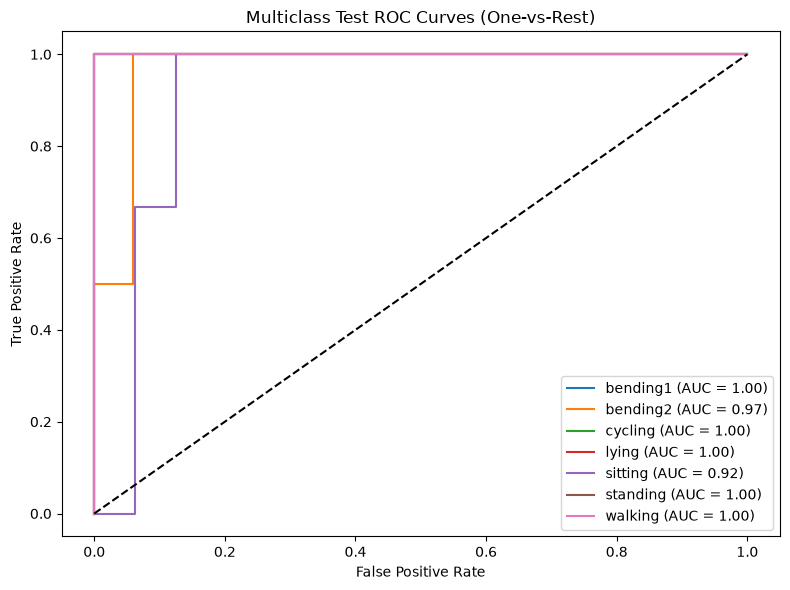

In [23]:
multi_probabilities = best_multi_model.predict_proba(X_test_multi)
classes = best_multi_model.classes_

plt.figure(figsize = (8, 6))

for i, activity in enumerate(classes):
    binary_labels = (y_test_multi == activity).astype(int)

    fpr, tpr, _ = roc_curve(binary_labels, multi_probabilities[:, i])

    activity_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label = f'{activity} (AUC = {activity_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass Test ROC Curves (One-vs-Rest)')
plt.legend(loc = 'lower right')
plt.tight_layout()
plt.show()

The best model uses $l = 2$ and $C = 100$, with a test error of 15.79%. Confusion matrix rows show actual classes, and columns show predictions. ROC curves use one-vs-rest. Four-fold stratified CV was used because bending2 has only four training instances.

#### ii. Naive Bayes

In [24]:
nb_results = []

best_gaussian_score = -1
best_multinomial_score = -1

for l in range(1, 21):
    X, y = extract_multiclass_feature(train_files, l)

    gaussian = GaussianNB()
    multinomial = MultinomialNB()

    gaussian_score = cross_val_score(gaussian, X, y, cv = cv_multi, scoring = 'accuracy').mean()
    multinomial_score = cross_val_score(multinomial, X, y, cv = cv_multi, scoring = 'accuracy').mean()

    nb_results.append({'l' : l, 'Gaussian CV Accuracy' : gaussian_score, 'Multinomial CV Accuracy' : multinomial_score})

    if gaussian_score > best_gaussian_score:
        best_gaussian_score = gaussian_score
        best_gaussian_l = l

    if multinomial_score > best_multinomial_score:
        best_multinomial_score = multinomial_score
        best_multinomial_l = l

nb_results_df = pd.DataFrame(nb_results)
display(nb_results_df)

print('Gaussian best l:', best_gaussian_l)
print('Gaussian best CV accuracy:', best_gaussian_score)

print('Multinomial best l:', best_multinomial_l)
print('Multinomial best CV accuracy:', best_multinomial_score)

,l,Gaussian CV Accuracy,Multinomial CV Accuracy
0,1,0.856209,0.839869
1,2,0.796569,0.810458
2,3,0.694444,0.781046
3,4,0.665033,0.795752
4,5,0.563725,0.809641
5,6,0.695261,0.794935
6,7,0.679739,0.810458
7,8,0.693627,0.795752
8,9,0.607843,0.781863
9,10,0.636438,0.795752


Gaussian best l: 1
Gaussian best CV accuracy: 0.8562091503267973
Multinomial best l: 1
Multinomial best CV accuracy: 0.8398692810457516


In [25]:
X_train_gaussian, y_train_gaussian = extract_multiclass_feature(train_files, best_gaussian_l)
X_test_gaussian, y_test_gaussian = extract_multiclass_feature(test_files, best_gaussian_l)

best_gaussian_model = GaussianNB()
best_gaussian_model.fit(X_train_gaussian, y_train_gaussian)

gaussian_predictions = best_gaussian_model.predict(X_test_gaussian)
gaussian_test_accuracy = accuracy_score(y_test_gaussian, gaussian_predictions)

X_train_multinomial, y_train_multinomial = extract_multiclass_feature(train_files, best_multinomial_l)
X_test_multinomial, y_test_multinomial = extract_multiclass_feature(test_files, best_multinomial_l)

best_multinomial_model = MultinomialNB()
best_multinomial_model.fit(X_train_multinomial, y_train_multinomial)

multinomial_predictions = best_multinomial_model.predict(X_test_multinomial)
multinomial_test_accuracy = accuracy_score(y_test_multinomial, multinomial_predictions)

print('Gaussian test accuracy:', gaussian_test_accuracy)
print('Gaussian test error:', 1 - gaussian_test_accuracy)

print('Multinomial test accuracy:', multinomial_test_accuracy)
print('Multinomial test error:', 1 - multinomial_test_accuracy)

Gaussian test accuracy: 0.8947368421052632
Gaussian test error: 0.10526315789473684
Multinomial test accuracy: 0.8947368421052632
Multinomial test error: 0.10526315789473684


In [26]:
print('Same predictions:', np.array_equal(gaussian_predictions, multinomial_predictions))

Same predictions: False


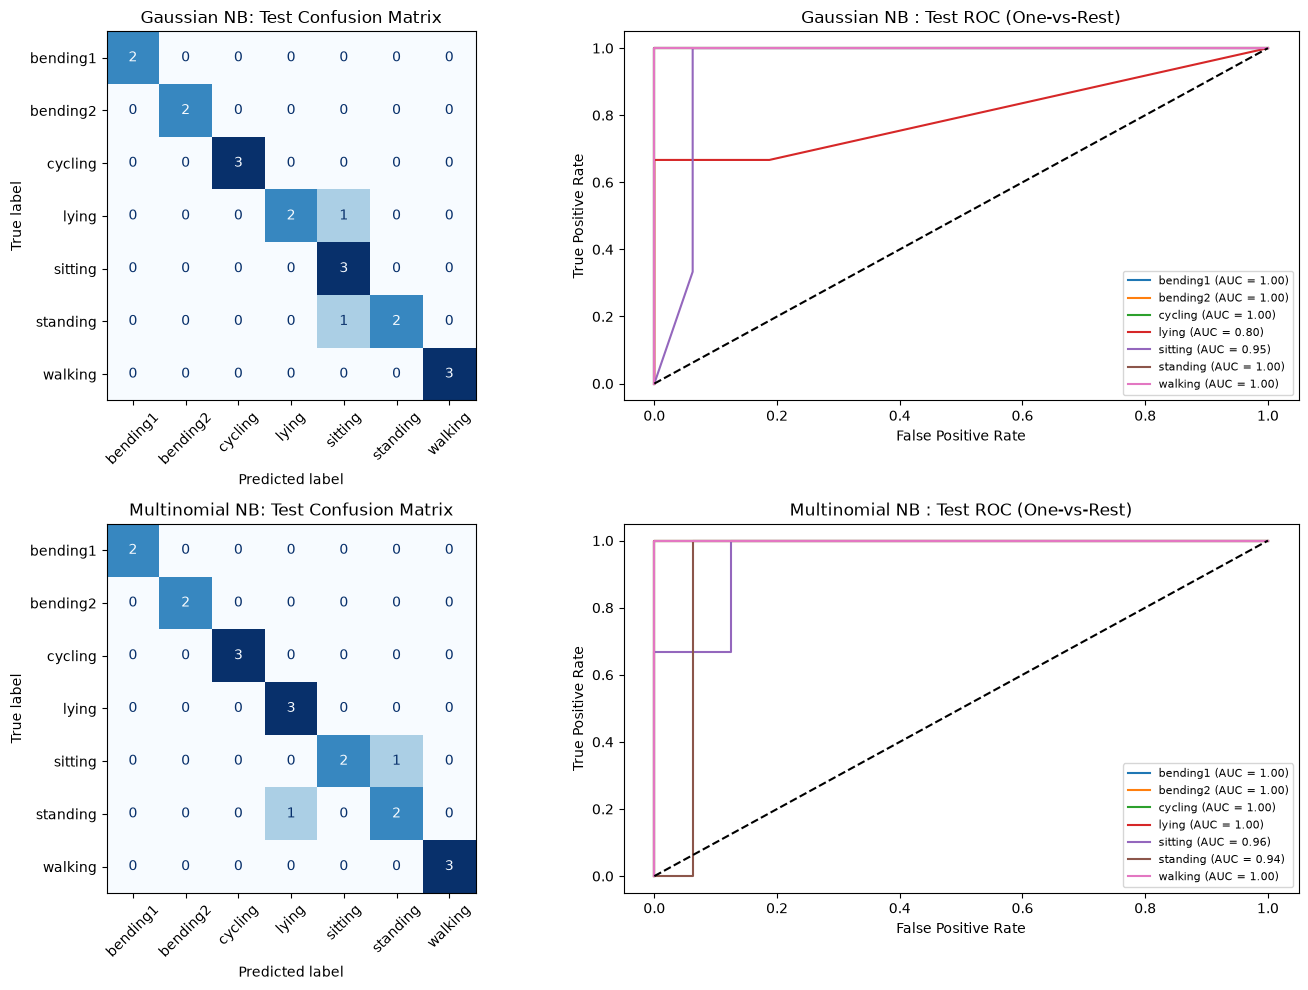

In [27]:
datasets = [('Gaussian NB', best_gaussian_model, X_test_gaussian, y_test_gaussian), 
            ('Multinomial NB', best_multinomial_model, X_test_multinomial, y_test_multinomial)]

fig, axes = plt.subplots(2, 2, figsize = (14, 10))

for row, (name, model, X, y) in enumerate(datasets):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)

    ConfusionMatrixDisplay.from_predictions(y, predictions, labels = model.classes_, cmap = 'Blues', colorbar = False, xticks_rotation = 45, ax = axes[row, 0])
    axes[row, 0].set_title(f'{name}: Test Confusion Matrix')

    for i, activity in enumerate(model.classes_):
        binary_labels = (y == activity).astype(int)

        fpr, tpr, _ = roc_curve(binary_labels, probabilities[:, i])

        activity_auc = auc(fpr, tpr)

        axes[row, 1].plot(fpr, tpr, label = f'{activity} (AUC = {activity_auc:.2f})')

    axes[row, 1].plot([0, 1], [0, 1], 'k--')
    axes[row, 1].set_xlabel('False Positive Rate')
    axes[row, 1].set_ylabel('True Positive Rate')
    axes[row, 1].set_title(f'{name} : Test ROC (One-vs-Rest)')
    axes[row, 1].legend(loc = 'lower right', fontsize = 8)

plt.tight_layout()
plt.show()

Both Naive Bayes models achieved 89.47% test accuracy, but made different errors. Gaussian NB had higher CV accuracy (85.62% vs. 83.99%).

#### iii. Comparison

Both Naive Bayes models performed best on the test set, achieving 89.47% accuracy. However, L1 multinomial logistic regression had the highest CV accuracy at 91.42%.

## 3. ISLR 4.8.3

Let $\pi_k=P(Y=k)$. By Bayes' theorem, we choose the class maximizing $\pi_k f_k(x)$. Taking logarithms and removing the common constant gives:

$$
\delta_k(x)
=
\log\pi_k-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the square:

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k.
$$

When class variances differ, the $x^2$ terms generally do not cancel when comparing classes. Therefore, the Bayes decision boundary is generally quadratic rather than linear.

## 4. ISLR 4.8.7

By Bayes' theorem, the common normalizing constants cancel:

$$
P(\text{Yes}\mid X=4)
=
\frac{
0.8e^{-\frac{(4-10)^2}{2\cdot36}}
}{
0.8e^{-\frac{(4-10)^2}{2\cdot36}}
+
0.2e^{-\frac{(4-0)^2}{2\cdot36}}
}
\approx 0.7519.
$$

Therefore, the probability that the company will issue a dividend is approximately 75.19%

## 5.1. Extra Practice ISLR 4.8.4

Not required for submission.

## 5.2. Extra Practice ISLR 4.8.9

Not required for submission.